In [1]:
import os
import xarray as xr
import datetime as dt
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
from matplotlib.colors import LinearSegmentedColormap

In [3]:
folder_project = 'E:/'
region = 'aac'

start_year = 2004
end_year = 2023
years = range(start_year, end_year+1)
#read ros monthly data
ros = xr.open_dataset(os.path.join(folder_project,'ROS_NC', 'ros_monthly_%s_%s_%s.nc'%(start_year, end_year, region)))
snow = xr.open_dataset(os.path.join(folder_project,'ROS_NC', 'snow_monthly_%s_%s_%s.nc'%(start_year, end_year, region)))
ice = xr.open_dataset(os.path.join(folder_project,'ROS_NC', 'ice_monthly_%s_%s_%s.nc'%(start_year, end_year, region)))



In [5]:
ice

<xarray.Dataset>
Dimensions:            (y: 508, x: 514, month: 12, year: 20)
Coordinates:
  * y                  (y) float64 1.17e+06 1.167e+06 ... -4.109e+05 -4.141e+05
  * x                  (x) float64 -2.323e+06 -2.32e+06 ... -7.203e+05
    Lambert_Conformal  int32 ...
    spatial_ref        int32 ...
  * month              (month) int64 1 2 3 4 5 6 7 8 9 10 11 12
  * year               (year) int32 2004 2005 2006 2007 ... 2020 2021 2022 2023
    projection         int32 ...
Data variables:
    ice                (year, month, y, x) float64 ...

In [8]:
subset.x

<xarray.DataArray 'x' (x: 514)>
array([-2323437.5, -2320312.5, -2317187.5, ...,  -726562.5,  -723437.5,
        -720312.5])
Coordinates:
  * x                  (x) float64 -2.323e+06 -2.32e+06 ... -7.203e+05
    Lambert_Conformal  int32 ...
    spatial_ref        int32 ...
    month              int64 10
    year               int32 2004
    projection         int32 ...

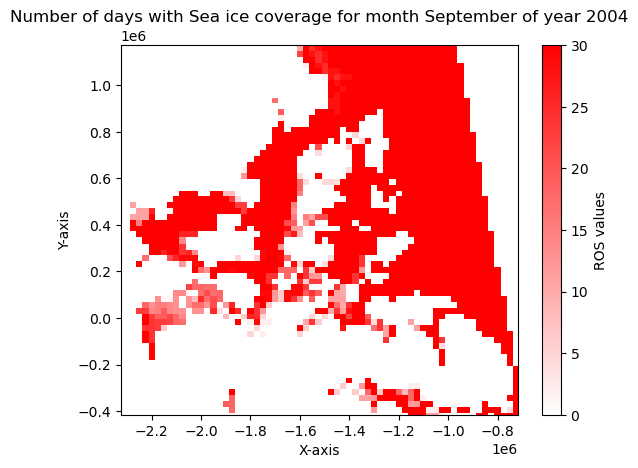

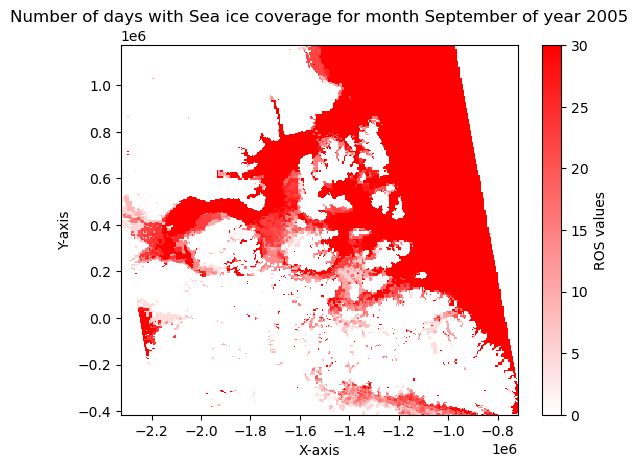

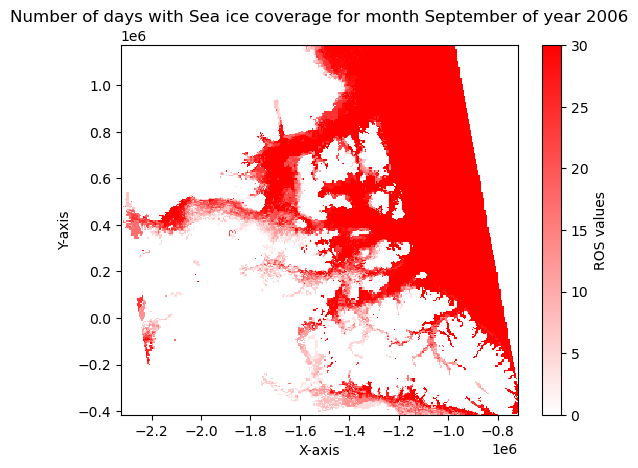

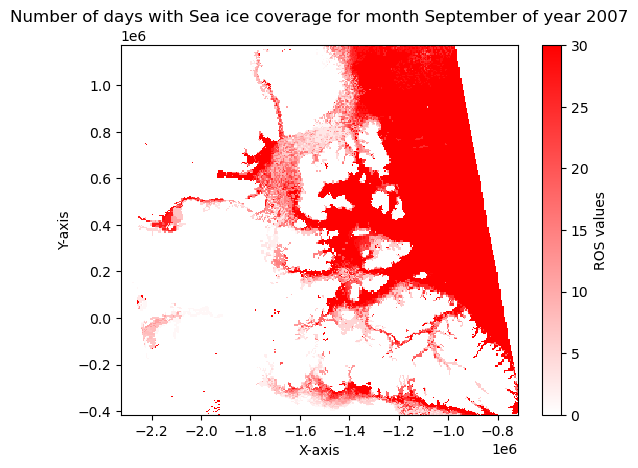

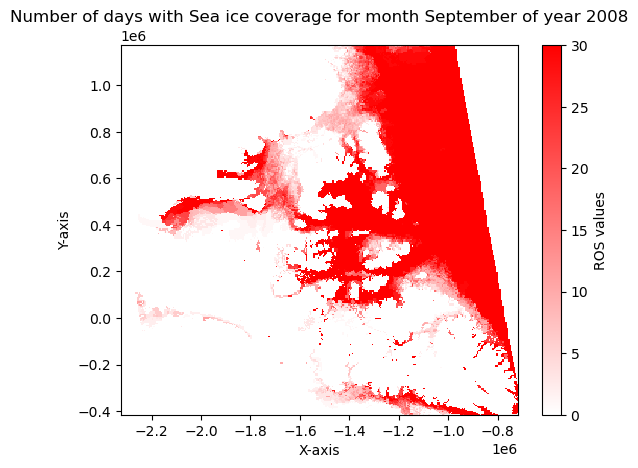

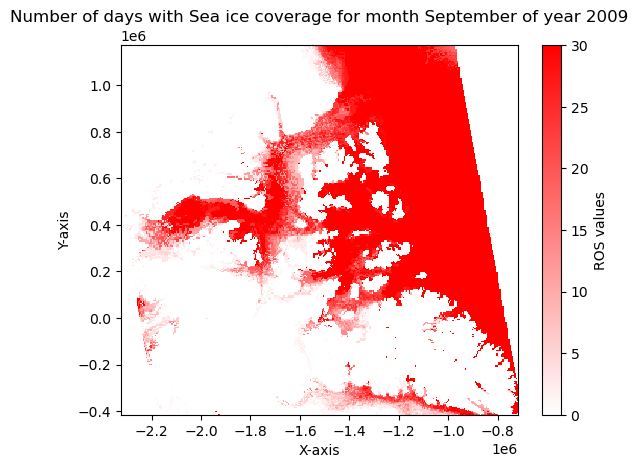

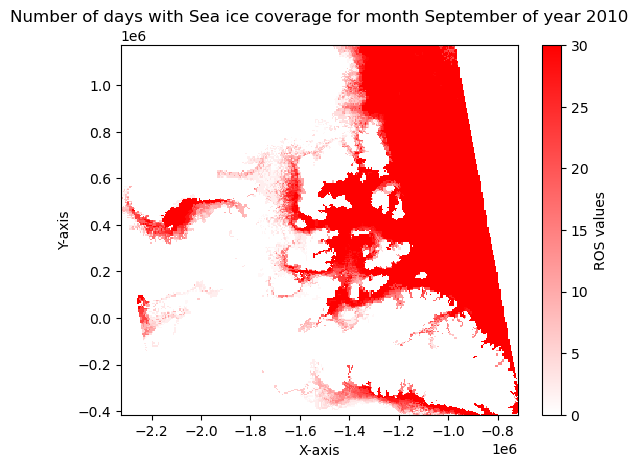

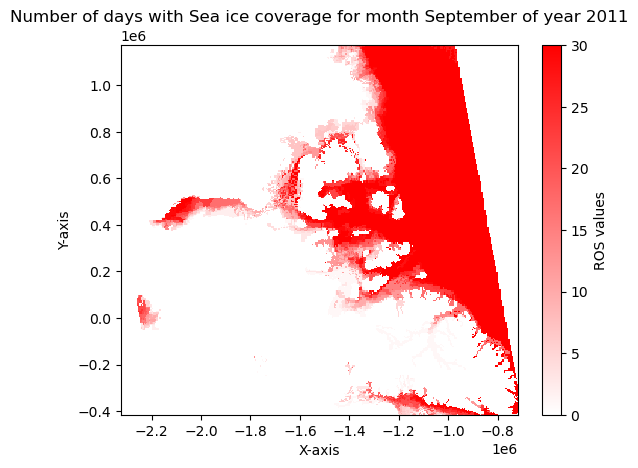

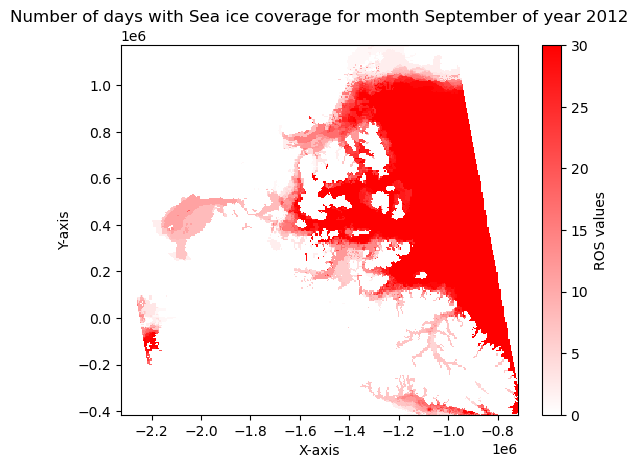

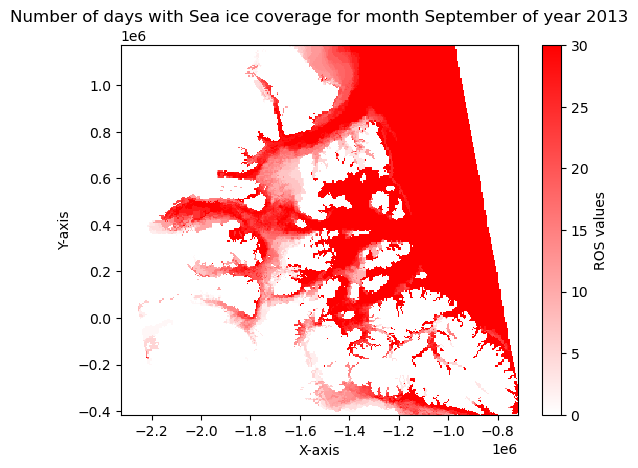

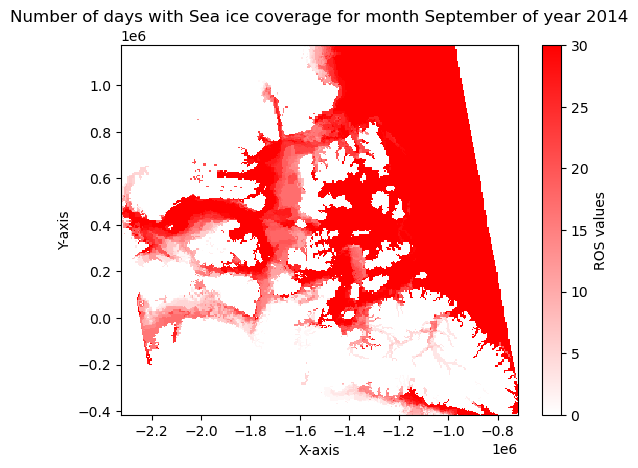

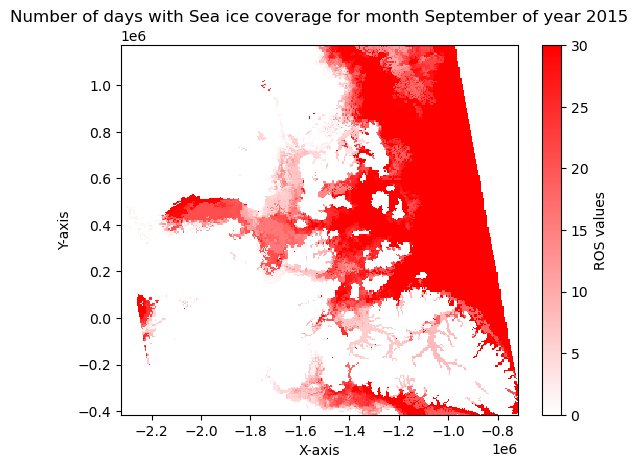

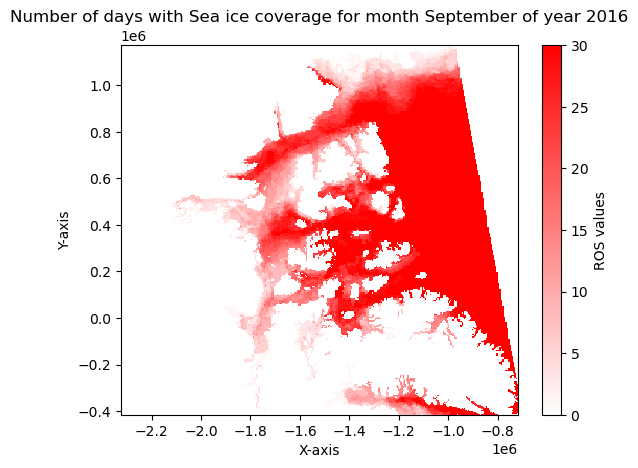

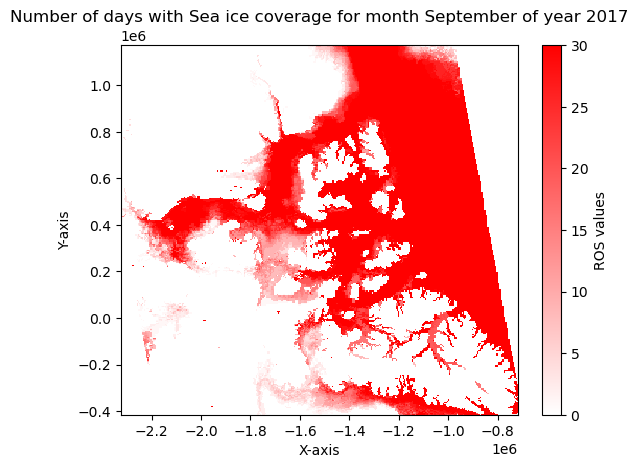

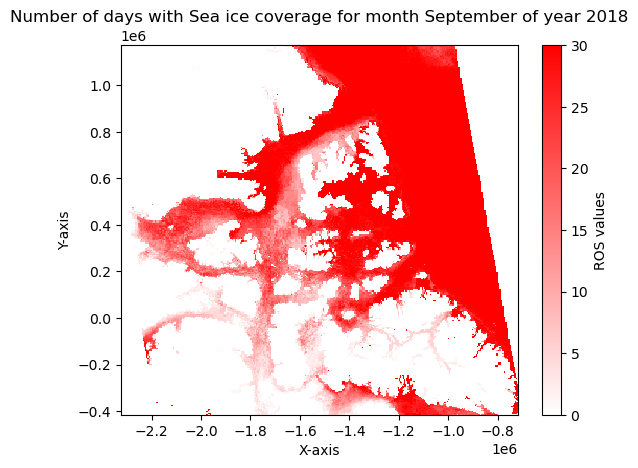

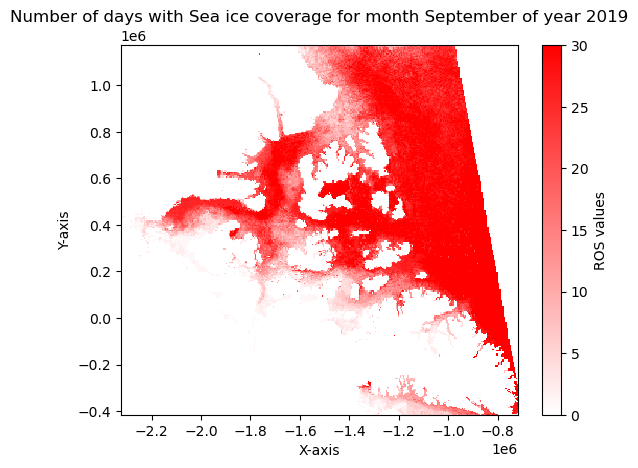

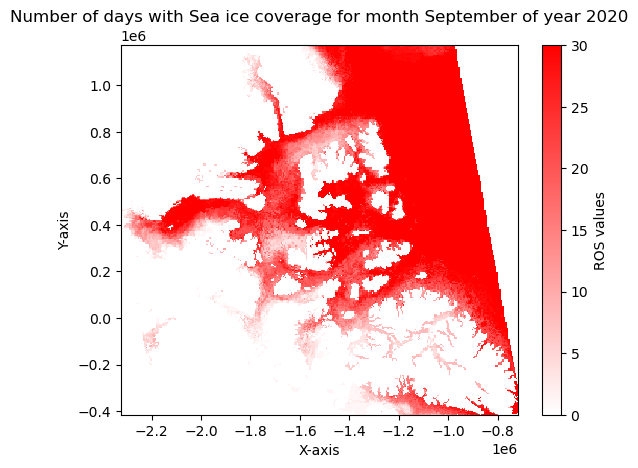

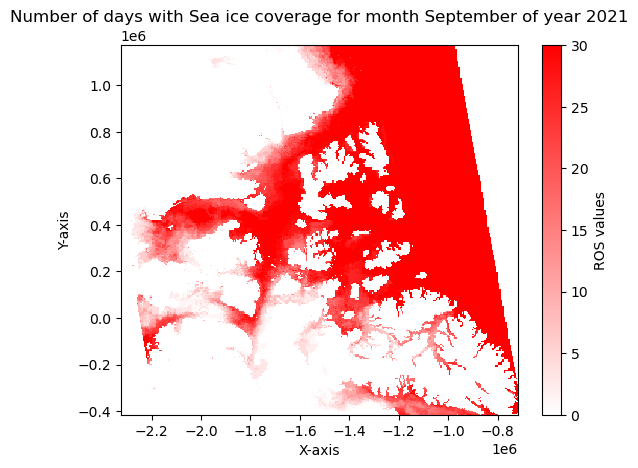

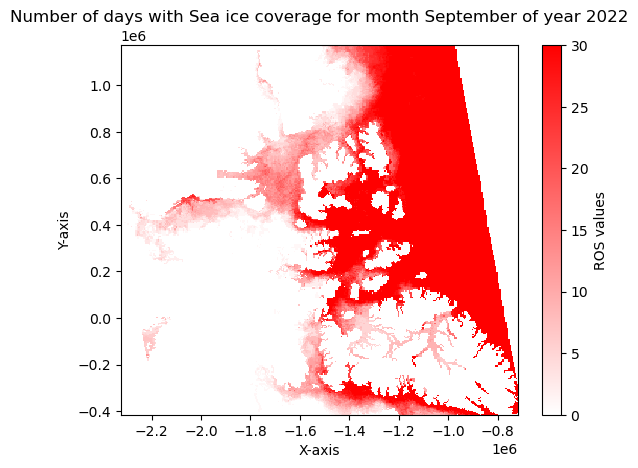

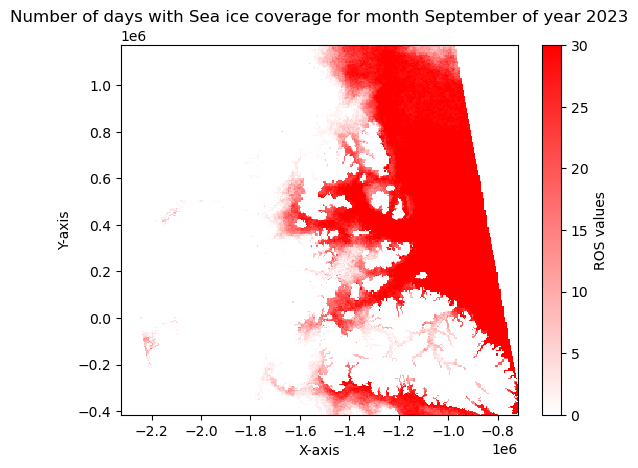

In [10]:

# Define the custom colormap from white to red
colors = [(1, 1, 1), (1, 0, 0)]  # From white to red
n_bins = 256  # Use 256 bins for the colormap
cmap_name = 'white_to_red'
cm = LinearSegmentedColormap.from_list(cmap_name, colors, N=n_bins)


#iterate over the months and plot the ice
for month in [9]:
    subset_month = ice.sel(month=month)
    for year in years:
        subset = subset_month.sel(year = year)
        
        # Plot the DataArray using pcolormesh
        fig, ax = plt.subplots()
        c = ax.pcolormesh(subset.x, subset.y, subset.ice, cmap=cm, vmin=0, vmax=30)

        # Add a colorbar
        cbar = fig.colorbar(c, ax=ax)
        cbar.set_label('ROS values')
        cbar.set_ticks([0, 5, 10, 15, 20, 25, 30])
        cbar.set_ticklabels(['0', '5', '10', '15', '20', '25', '30'])

        # Set labels and title
        ax.set_xlabel('X-axis')
        ax.set_ylabel('Y-axis')
        ax.set_title('Number of days with Sea ice coverage for month %s of year %s'%(str(dt.date(1900, month, 1).strftime('%B')), str(year)))

        #plt.show()
        
        #save the figure
        fig.savefig(os.path.join(folder_project, 'figures',str(dt.date(1900, month, 1).strftime('%B')), 'sea_ice_days_per_month_%s_%s.png'%(str(year), str(dt.date(1900, month, 1).strftime('%B')))))

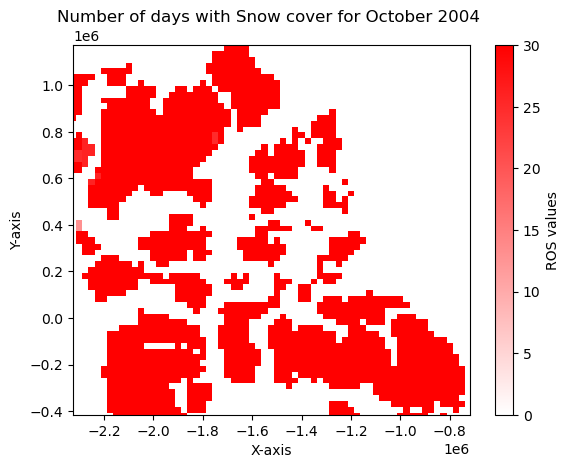

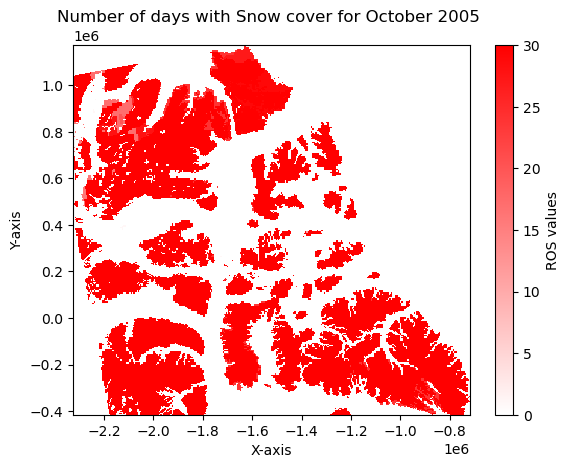

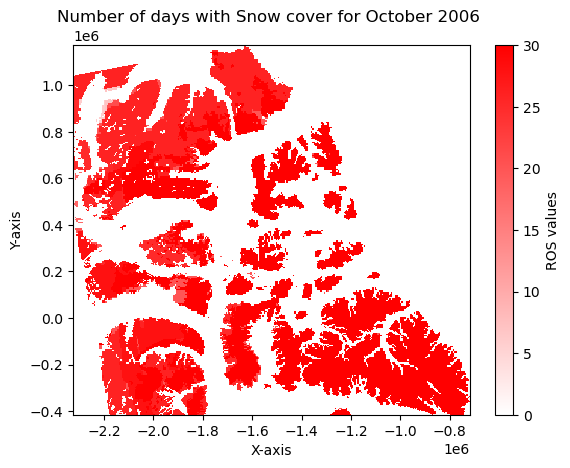

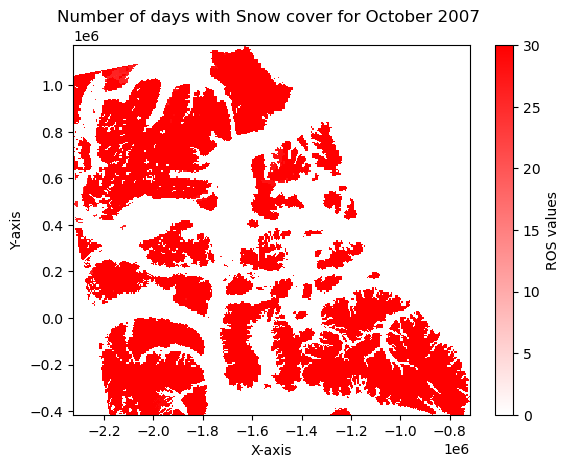

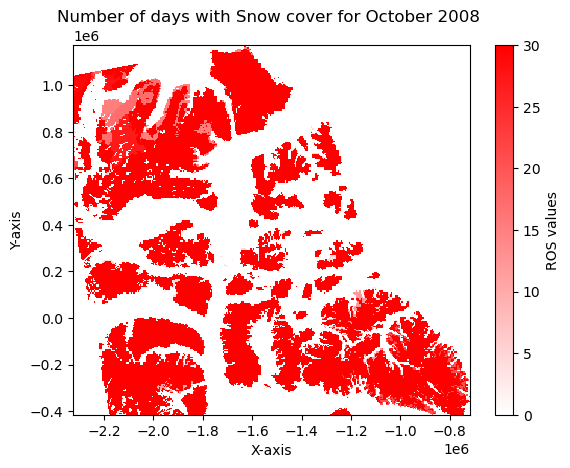

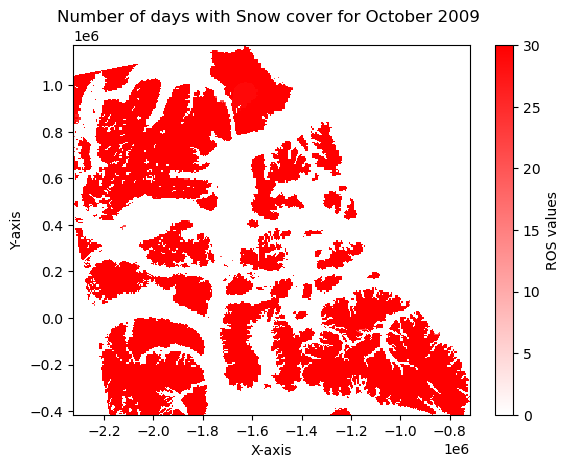

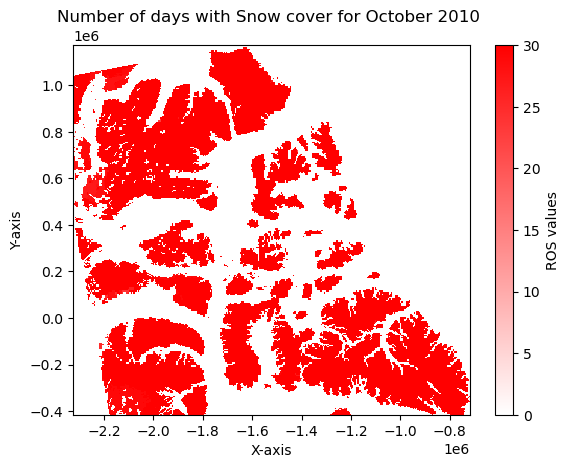

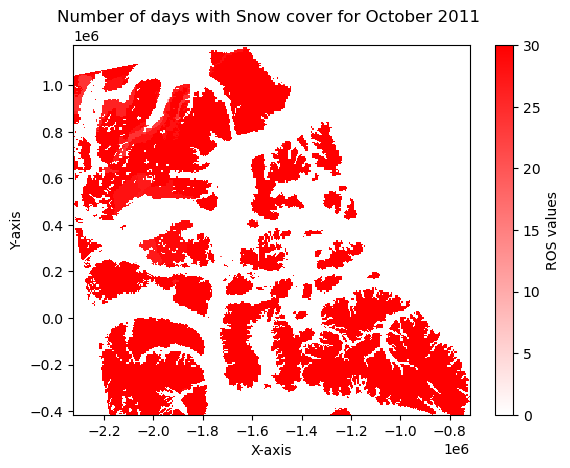

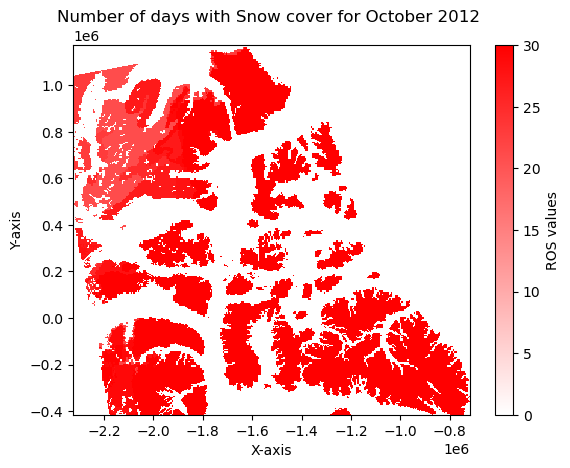

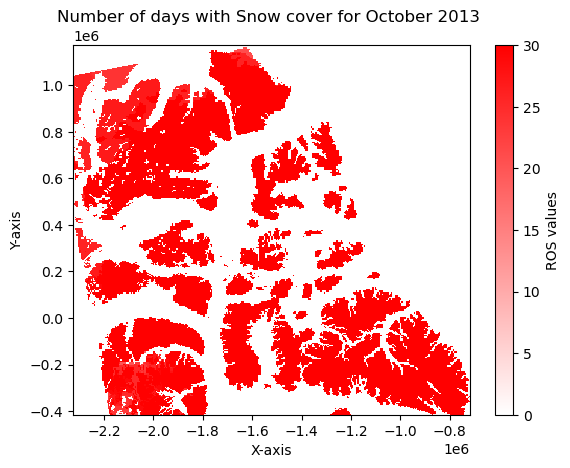

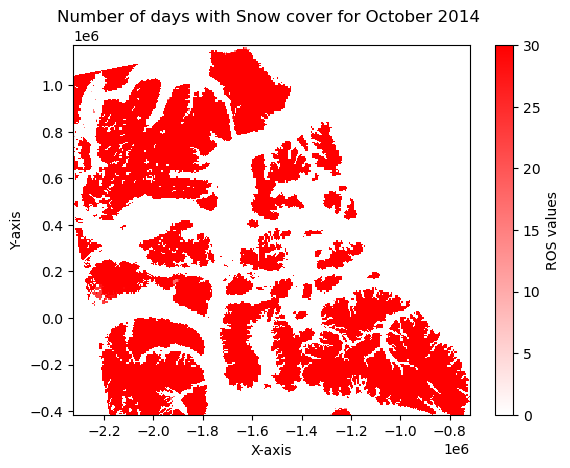

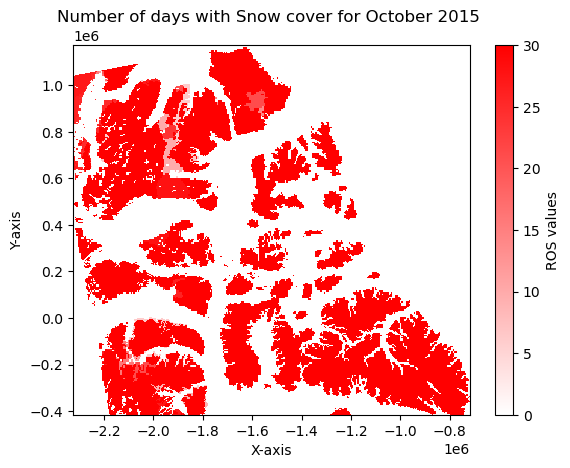

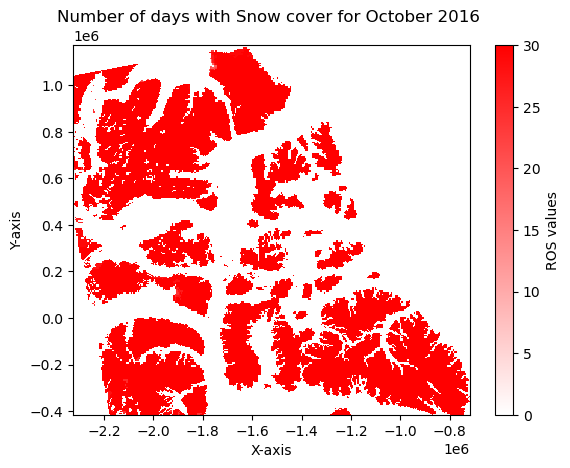

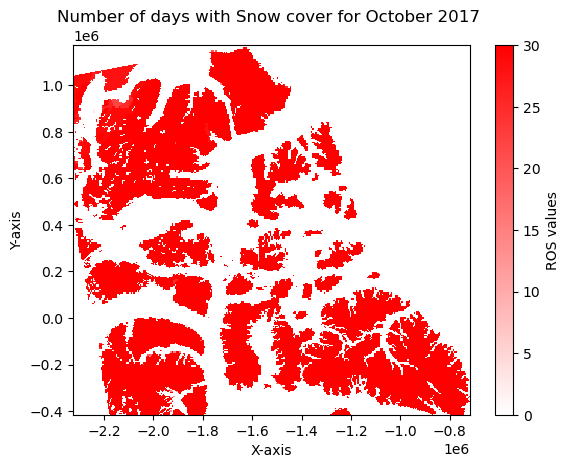

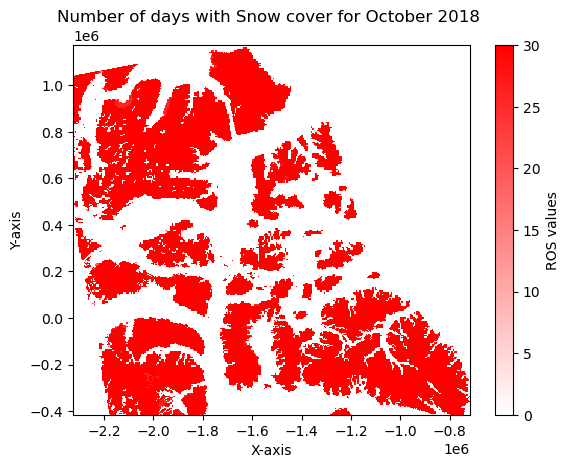

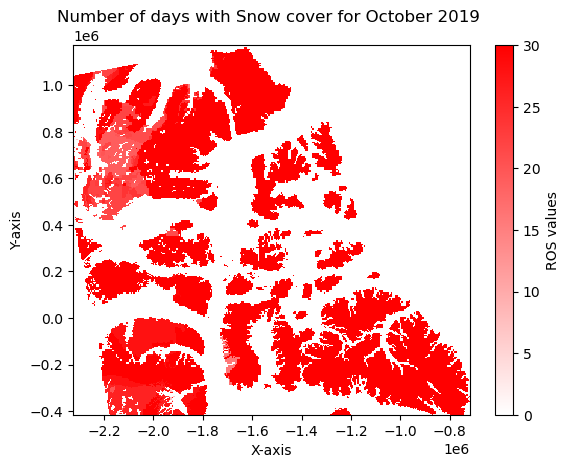

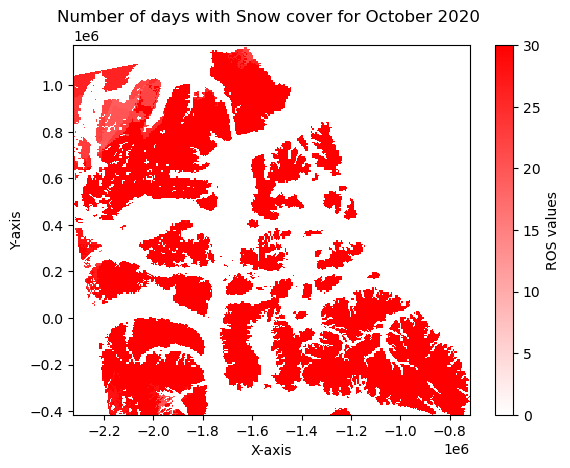

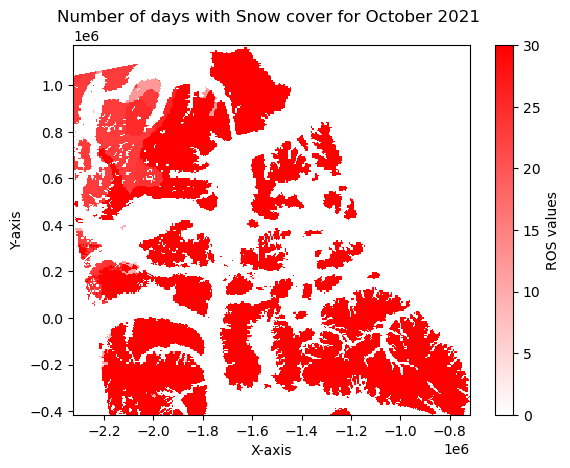

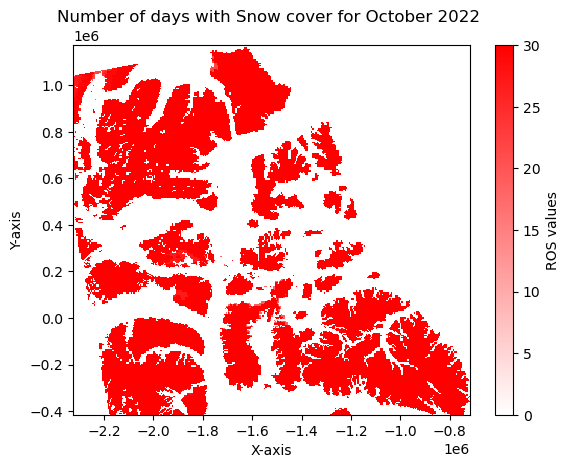

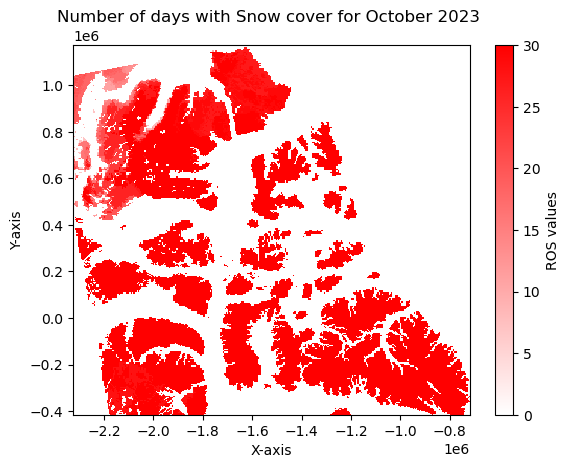

In [11]:

# Define the custom colormap from white to red
colors = [(1, 1, 1), (1, 0, 0)]  # From white to red
n_bins = 256  # Use 256 bins for the colormap
cmap_name = 'white_to_red'
cm = LinearSegmentedColormap.from_list(cmap_name, colors, N=n_bins)


#iterate over the months and plot the snow days
for month in [10]:
    subset_month = snow.sel(month=month)
    for year in years:
        subset = subset_month.sel(year = year)
        
        # Plot the DataArray using pcolormesh
        fig, ax = plt.subplots()
        c = ax.pcolormesh(subset.x, subset.y, subset.snow, cmap=cm, vmin=0, vmax=30)

        # Add a colorbar
        cbar = fig.colorbar(c, ax=ax)
        cbar.set_label('ROS values')
        cbar.set_ticks([0, 5, 10, 15, 20, 25, 30])
        cbar.set_ticklabels(['0', '5', '10', '15', '20', '25', '30'])

        # Set labels and title
        ax.set_xlabel('X-axis')
        ax.set_ylabel('Y-axis')
        ax.set_title('Number of days with Snow cover for %s %s '%(str(dt.date(1900, month, 1).strftime('%B')), str(year)))

        plt.show()

        #save the figure
        fig.savefig(os.path.join(folder_project, 'figures',str(dt.date(1900, month, 1).strftime('%B')), 'snow_days_per_month_%s_%s.png'%(str(year), str(dt.date(1900, month, 1).strftime('%B')))))

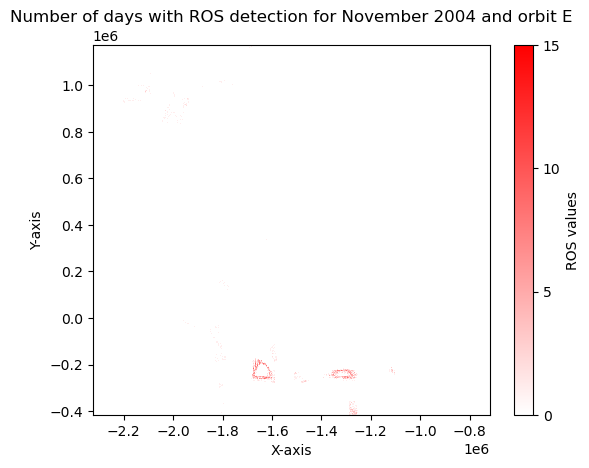

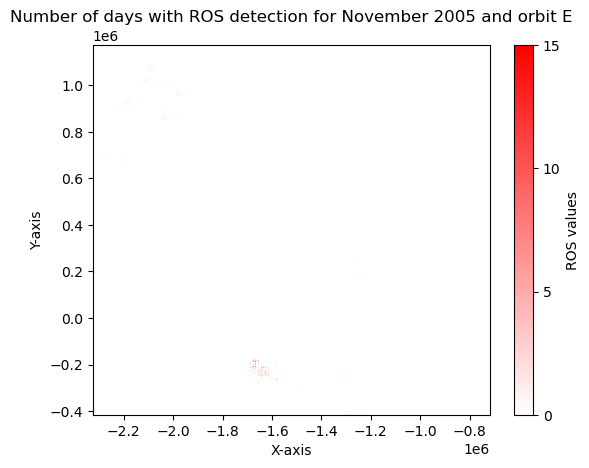

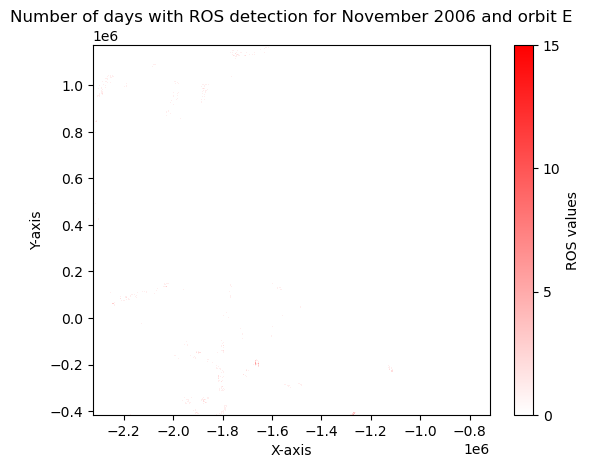

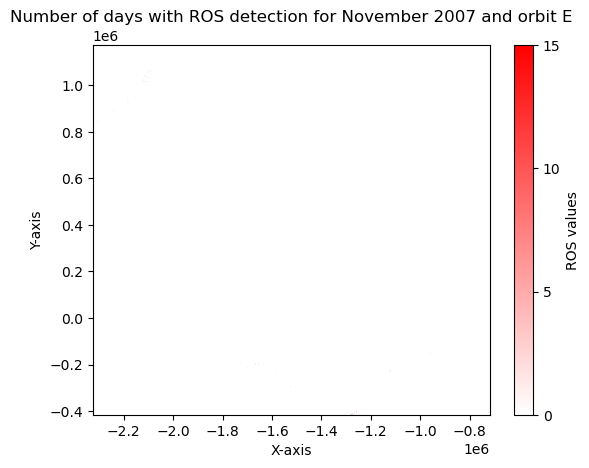

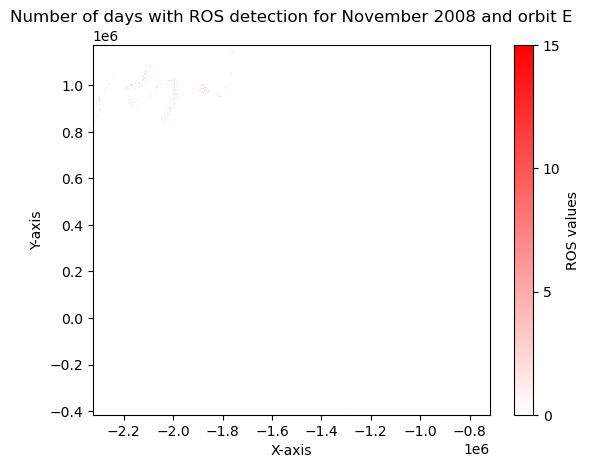

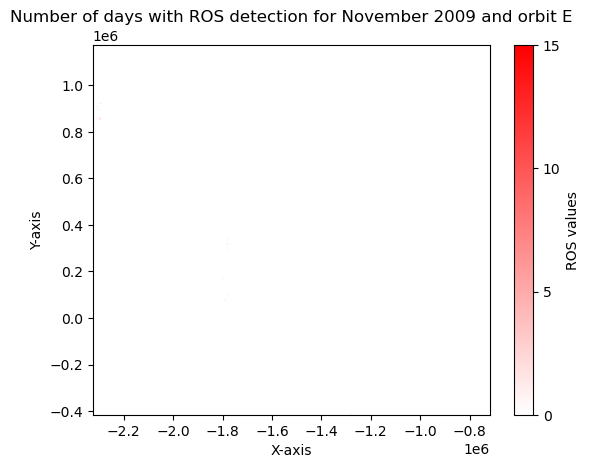

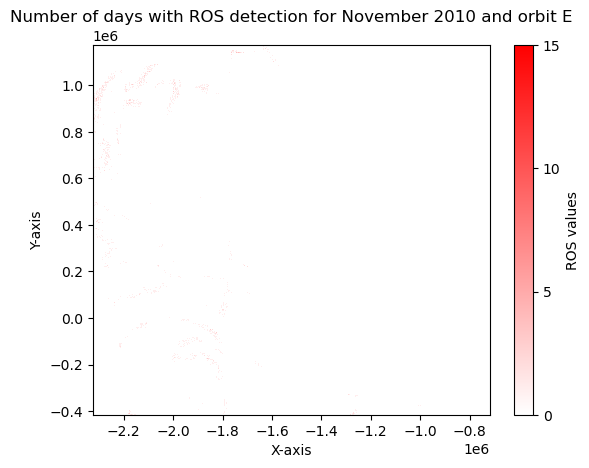

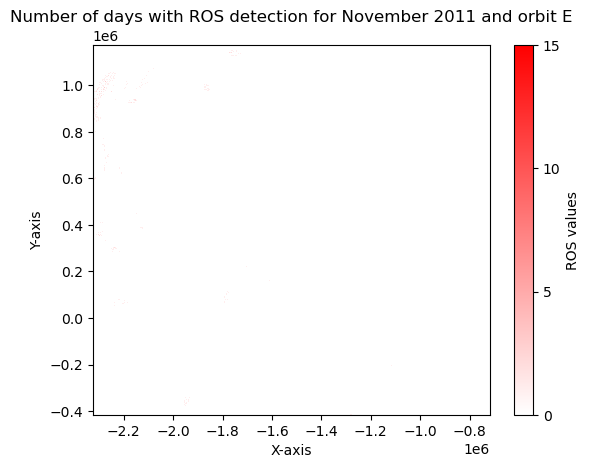

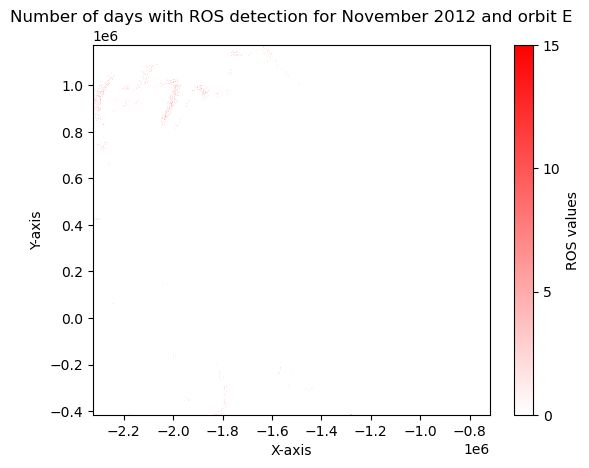

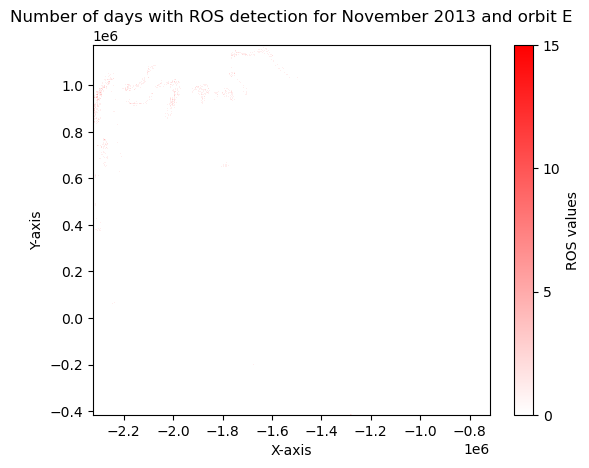

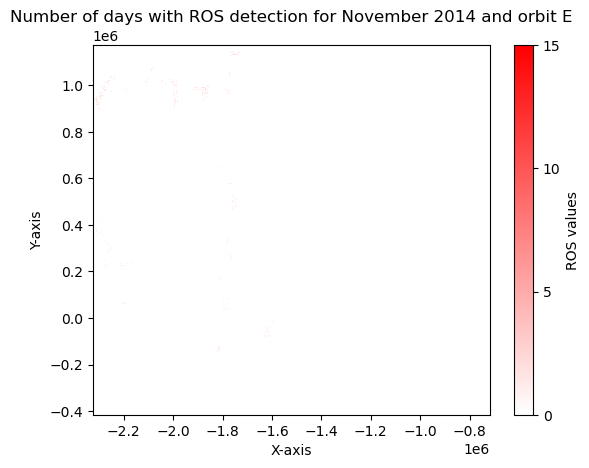

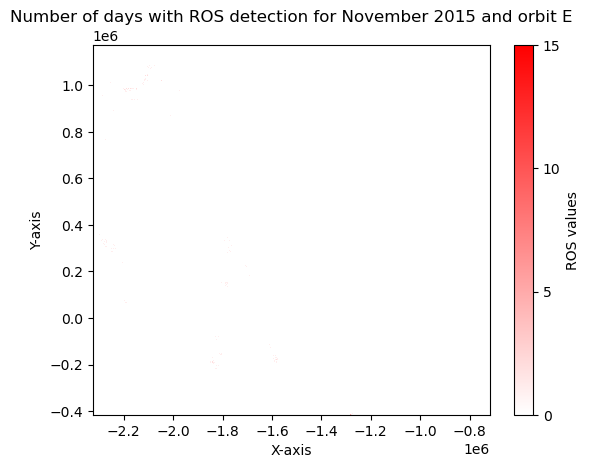

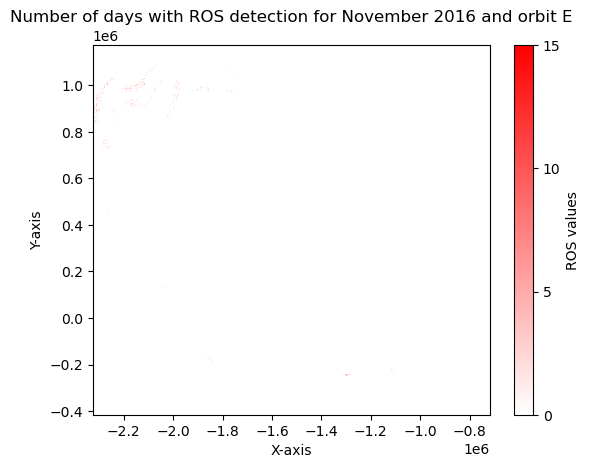

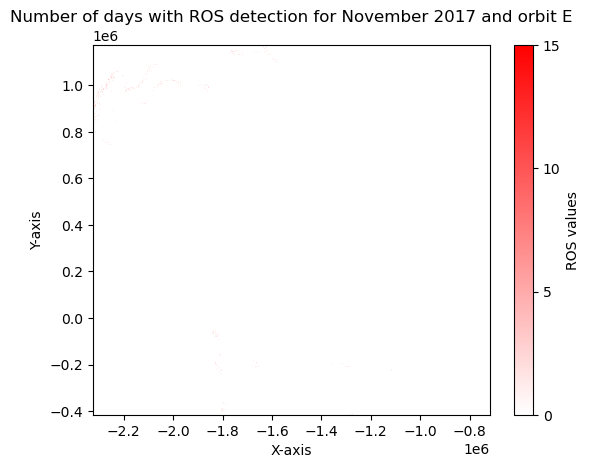

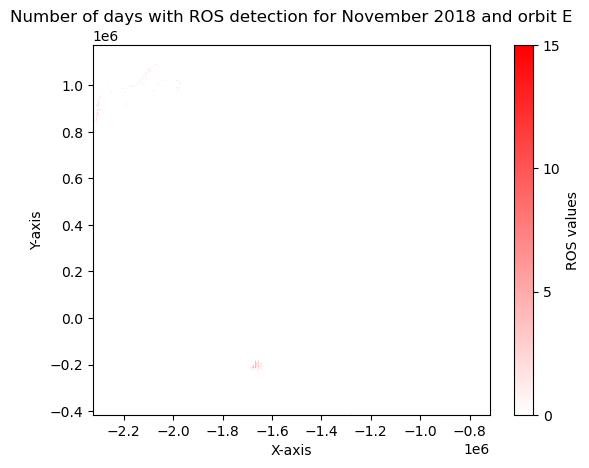

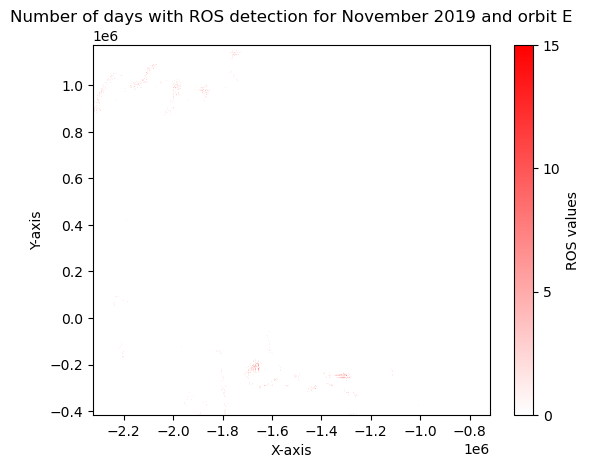

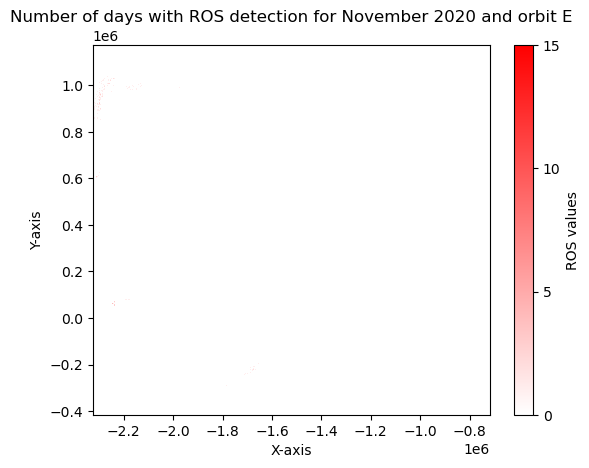

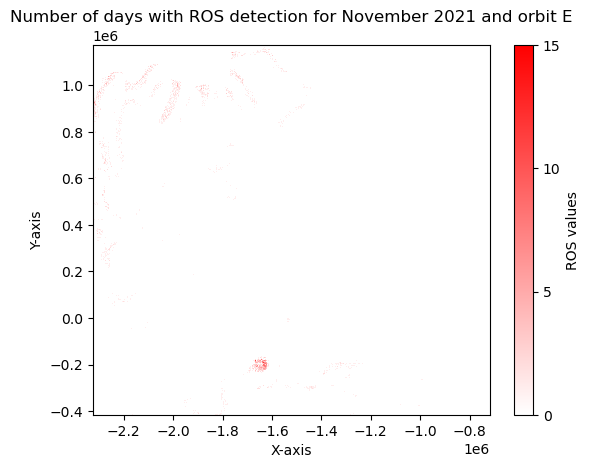

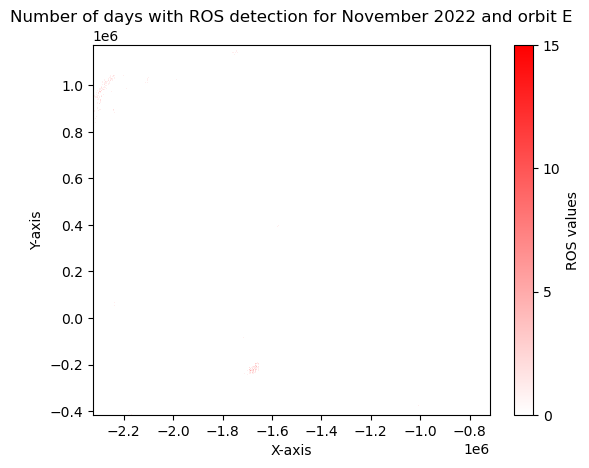

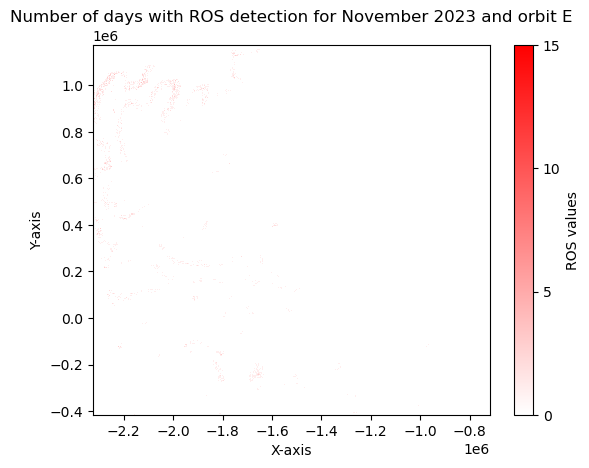

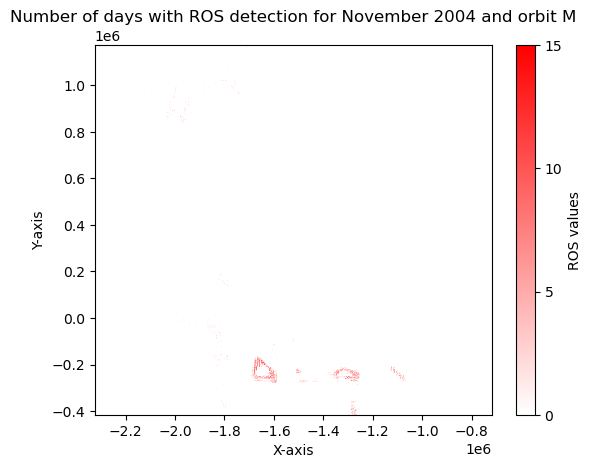

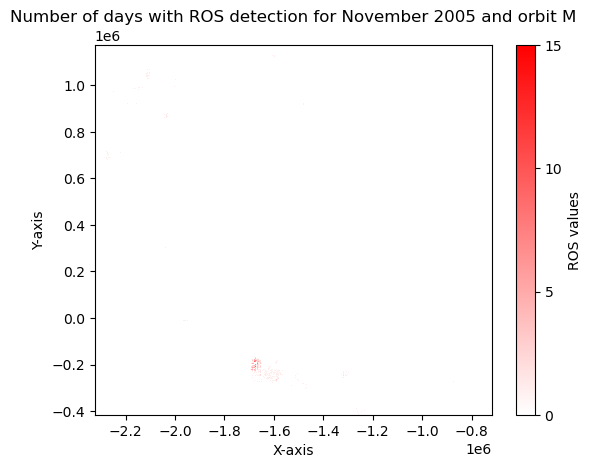

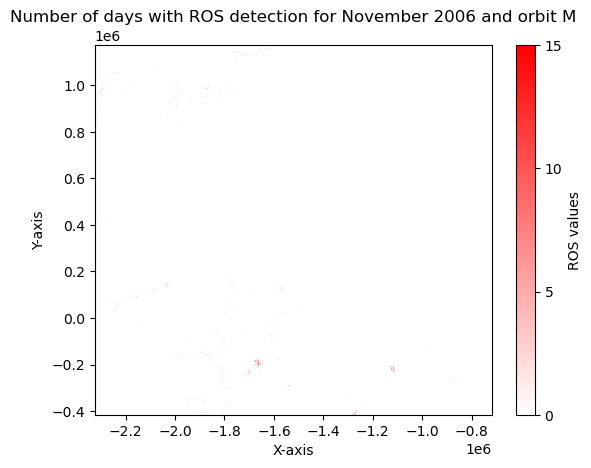

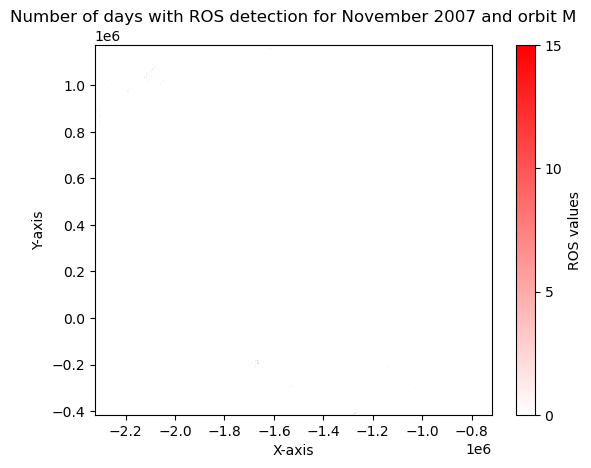

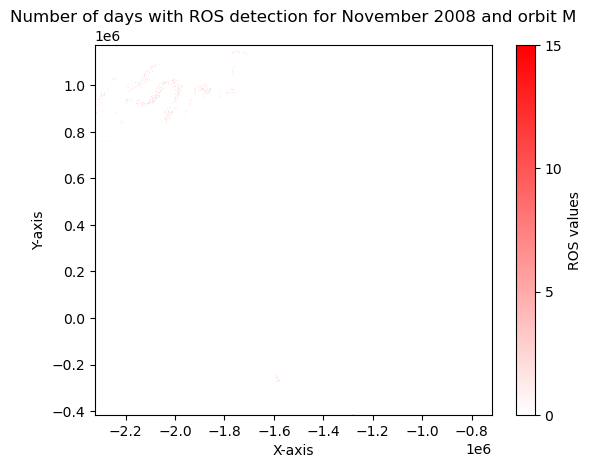

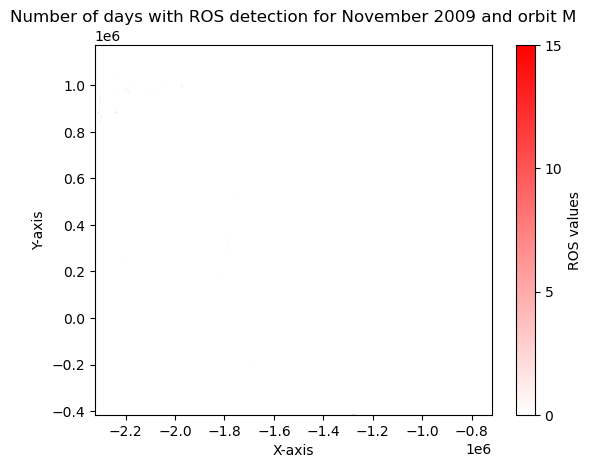

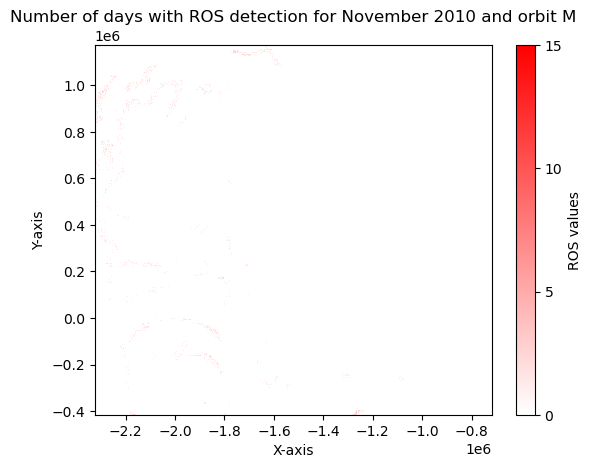

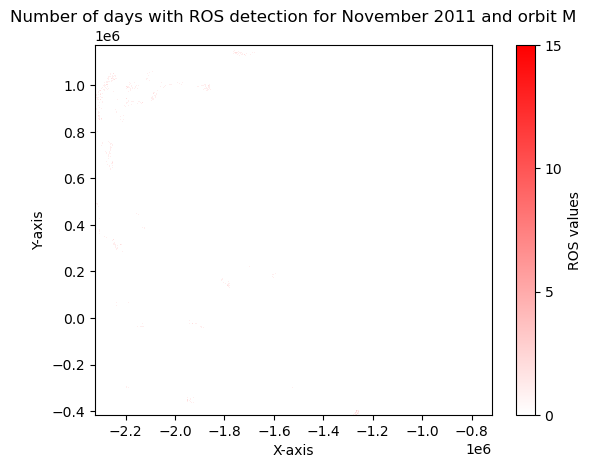

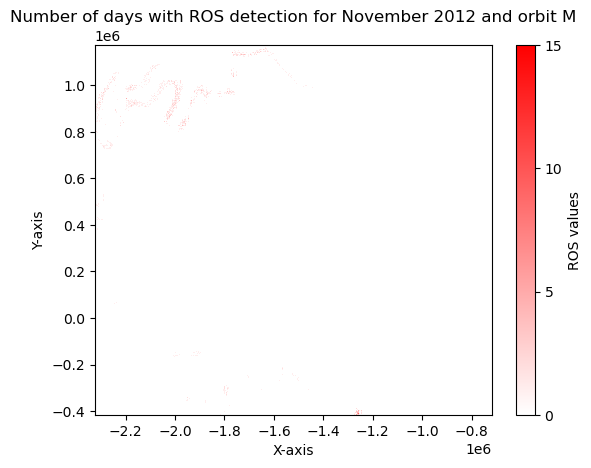

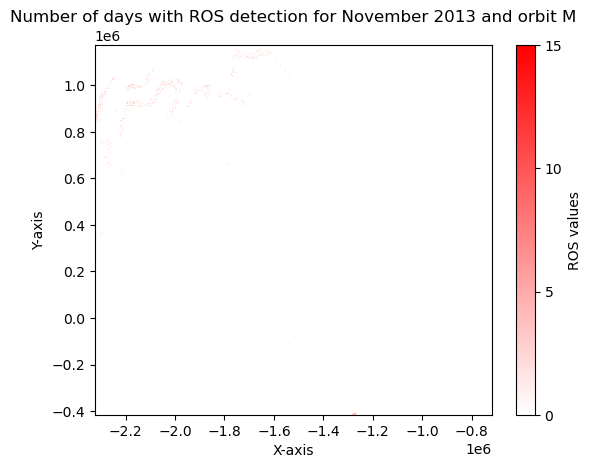

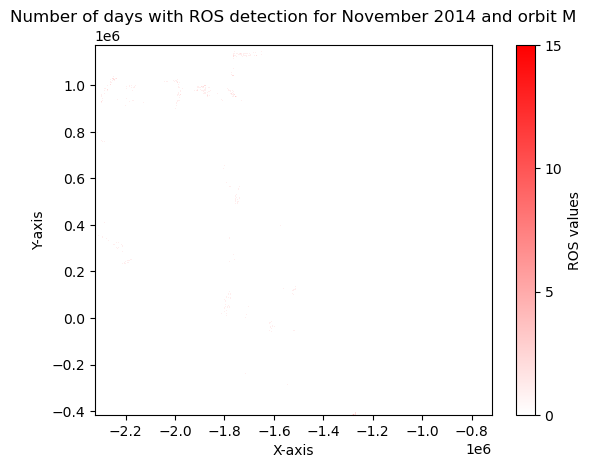

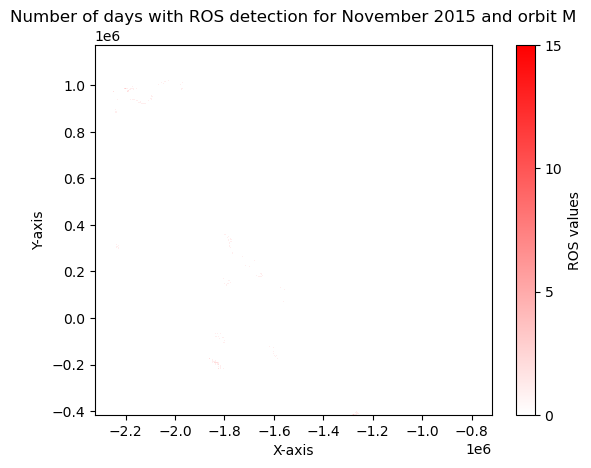

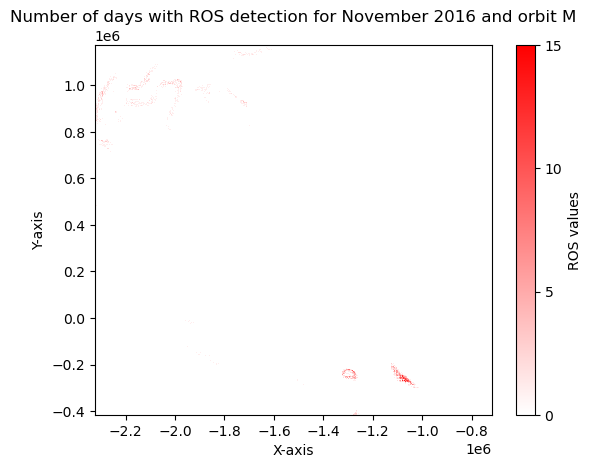

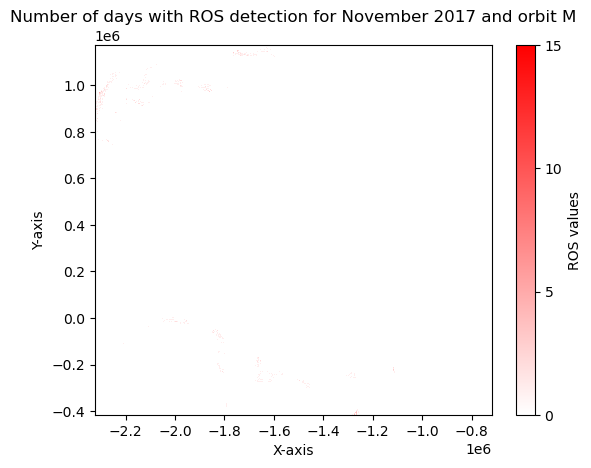

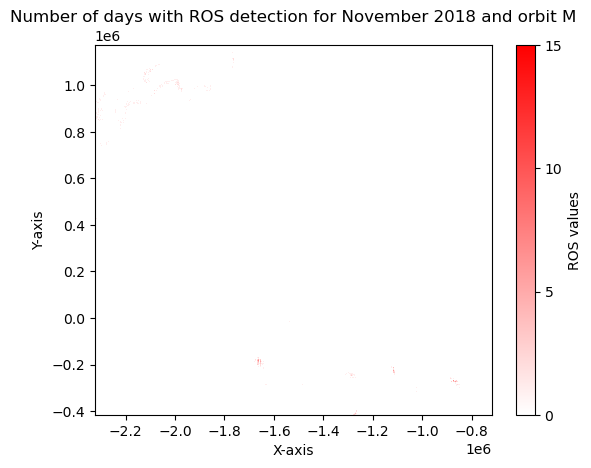

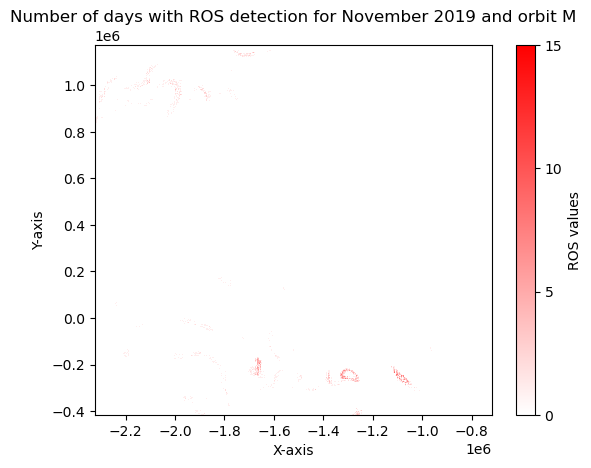

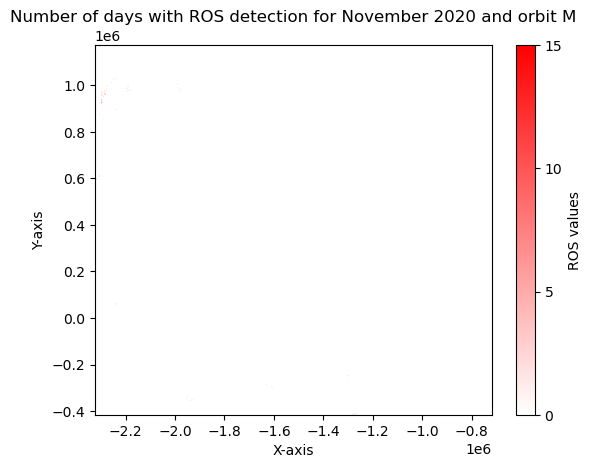

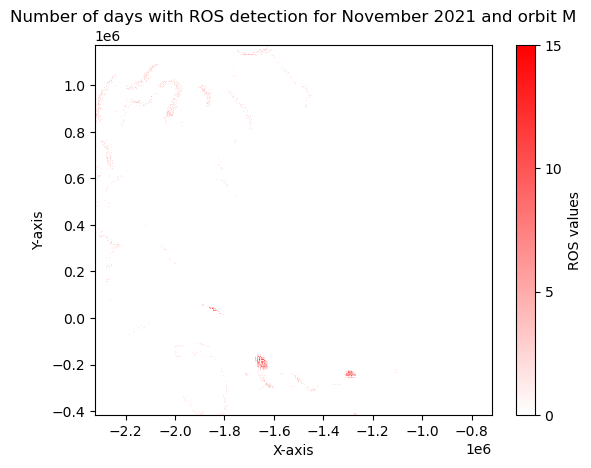

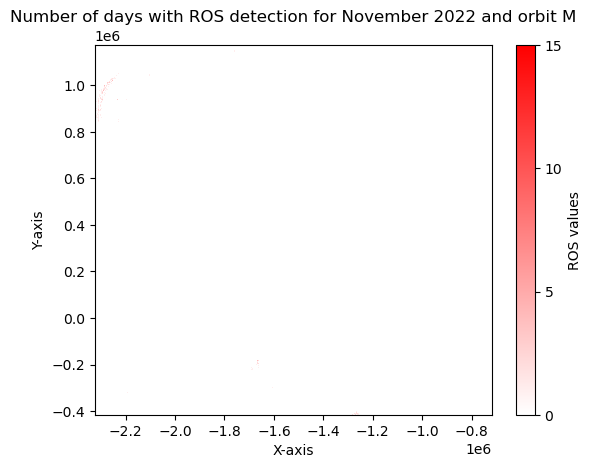

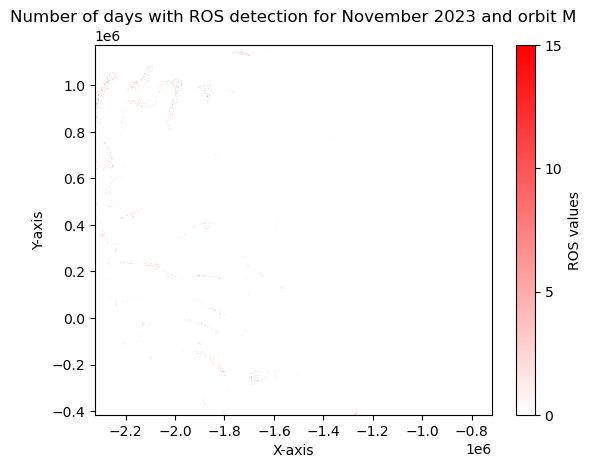

In [16]:
orbits = ['E', 'M']
# Define the custom colormap from white to red
colors = [(1, 1, 1), (1, 0, 0)]  # From white to red
n_bins = 256  # Use 256 bins for the colormap
cmap_name = 'white_to_red'
cm = LinearSegmentedColormap.from_list(cmap_name, colors, N=n_bins)

for orbit in orbits:
    subset_orbit = ros.sel(orbit=orbit)
    #iterate over the months and plot the ROS
    for month in [11]:
        subset_month = subset_orbit.sel(month=month)
        for year in years:
            subset = subset_month.sel(year = year)
            
            # Plot the DataArray using pcolormesh
            fig, ax = plt.subplots()
            c = ax.pcolormesh(subset.x, subset.y, subset.ROS, cmap=cm, vmin=0, vmax=15)

            # Add a colorbar
            cbar = fig.colorbar(c, ax=ax)
            cbar.set_label('ROS values')
            cbar.set_ticks([0, 5, 10, 15])
            cbar.set_ticklabels(['0', '5', '10', '15'])

            # Set labels and title
            ax.set_xlabel('X-axis')
            ax.set_ylabel('Y-axis')
            ax.set_title('Number of days with ROS detection for %s %s and orbit %s'%(str(dt.date(1900, month, 1).strftime('%B')), str(year), orbit))

            plt.show()
             #save the figure
            fig.savefig(os.path.join(folder_project, 'figures',str(dt.date(1900, month, 1).strftime('%B')), 'ros_days_per_month_%s_%s_%s.png'%(str(year), str(dt.date(1900, month, 1).strftime('%B')), orbit)))
            

In [4]:
#write to netcdf
file_out = os.path.join(folder_project, 'ROS_NC', 'ros_%s_%s_2.nc'%(str(year), region))
ds.to_netcdf(file_out)

In [ ]:
#iterate from start_date for a number of days
time = datetime(2022,10,1)
nb_days = 30
orbit = 'M'

# Iterate over the range of dates
for i in range(nb_days):
    current_date = time + timedelta(days=i)
    print(current_date.strftime('%Y-%m-%d'))

    ds['ROS'].sel(time=current_date, orbit=orbit).plot(vmin=0,vmax=1)
    plt.show()
#ds['GRP'].sel(time=time, orbit=orbit).plot(vmin=-5,vmax=5)
#plt.show()
